# Public-data EDA for an incident investigation assistant

Measured historical data; agents and Azure deployment are not demonstrated by this notebook. See `docs/evidence/eda/README.md` for changes, research and upload captions. Each source is independent.

In [1]:
import os
from pathlib import Path

if not Path("data/dataset_manifest.json").exists():
    os.chdir("..")
from scripts.eda_evidence import build

report = build(Path("data"), Path("docs/evidence/eda"))
print("Verified source runs:", len(report["runs"]))

Verified source runs: 7


## Inventory and missing values
Incident rows and event rows are different units. Null normalized timestamps do not prove raw dates are absent.

In [2]:
import pandas as pd

inventory = [
    {
        "source": r["dataset"],
        "table": k,
        "rows": t["rows"],
        "duplicate_keys": t["duplicate_source_keys"],
    }
    for r in report["runs"]
    for k, t in r["tables"].items()
]
display(pd.DataFrame(inventory))
missing = [
    {"source": r["dataset"], "table": k, "field": f, "missing_percent": v}
    for r in report["runs"]
    for k, t in r["tables"].items()
    for f, v in t["missing_percent"].items()
    if v
]
display(pd.DataFrame(missing))

,source,table,rows,duplicate_keys
0,bpi-2013,incidents,7554,0
1,bpi-2013,events,65533,0
2,bpi-2014,incidents,46606,0
3,loghub-apache,logs,2000,0
4,loghub-bgl,logs,2000,0
5,loghub-hdfs,logs,2000,0
6,loghub-openstack,logs,2000,0
7,loghub-zookeeper,logs,2000,0


,source,table,field,missing_percent
0,bpi-2013,incidents,closed_at,26.225
1,bpi-2014,incidents,opened_at,100.000
2,bpi-2014,incidents,closed_at,100.000
3,loghub-apache,logs,occurred_at,100.000
4,loghub-apache,logs,component,100.000
5,loghub-hdfs,logs,occurred_at,100.000
6,loghub-openstack,logs,occurred_at,100.000
7,loghub-zookeeper,logs,occurred_at,100.000


## Measured durations and source-order activity paths
Complete pairs only; no SLA thresholds or original creation-time claims. Repeated activity does not establish failure. Percentiles use linear interpolation.

In [3]:
for r in report["runs"]:
    for _k, t in r["tables"].items():
        for field in ["observed_duration_hours", "lifecycle", "message_length_chars"]:
            if field in t:
                print(r["dataset"], field, t[field])

bpi-2013 observed_duration_hours {'count': 5573, 'min': 0.02638888888888889, 'median': 199.33388888888888, 'p90': 671.8883333333339, 'p95': 1138.7679444444436, 'max': 18512.4425}
bpi-2013 lifecycle {'ordering': 'source_record within source and incident; not inferred time order', 'events_per_incident': {'count': 7554, 'min': 1.0, 'median': 6.0, 'p90': 17.0, 'p95': 23.0, 'max': 123.0}, 'unique_paths': 535, 'cases_with_repeated_activity': 7539, 'top_transitions': [{'from': 'Accepted', 'to': 'Accepted', 'count': 32565}, {'from': 'Accepted', 'to': 'Completed', 'count': 7544}, {'from': 'Queued', 'to': 'Queued', 'count': 7033}, {'from': 'Completed', 'to': 'Completed', 'count': 6321}, {'from': 'Completed', 'to': 'Queued', 'count': 4508}, {'from': 'Completed', 'to': 'Unmatched', 'count': 3}, {'from': 'Accepted', 'to': 'Queued', 'count': 3}, {'from': 'Queued', 'to': 'Unmatched', 'count': 2}], 'top_path_counts': [1754, 525, 392, 392, 300, 252, 230, 227, 174, 149]}
bpi-2014 observed_duration_hours

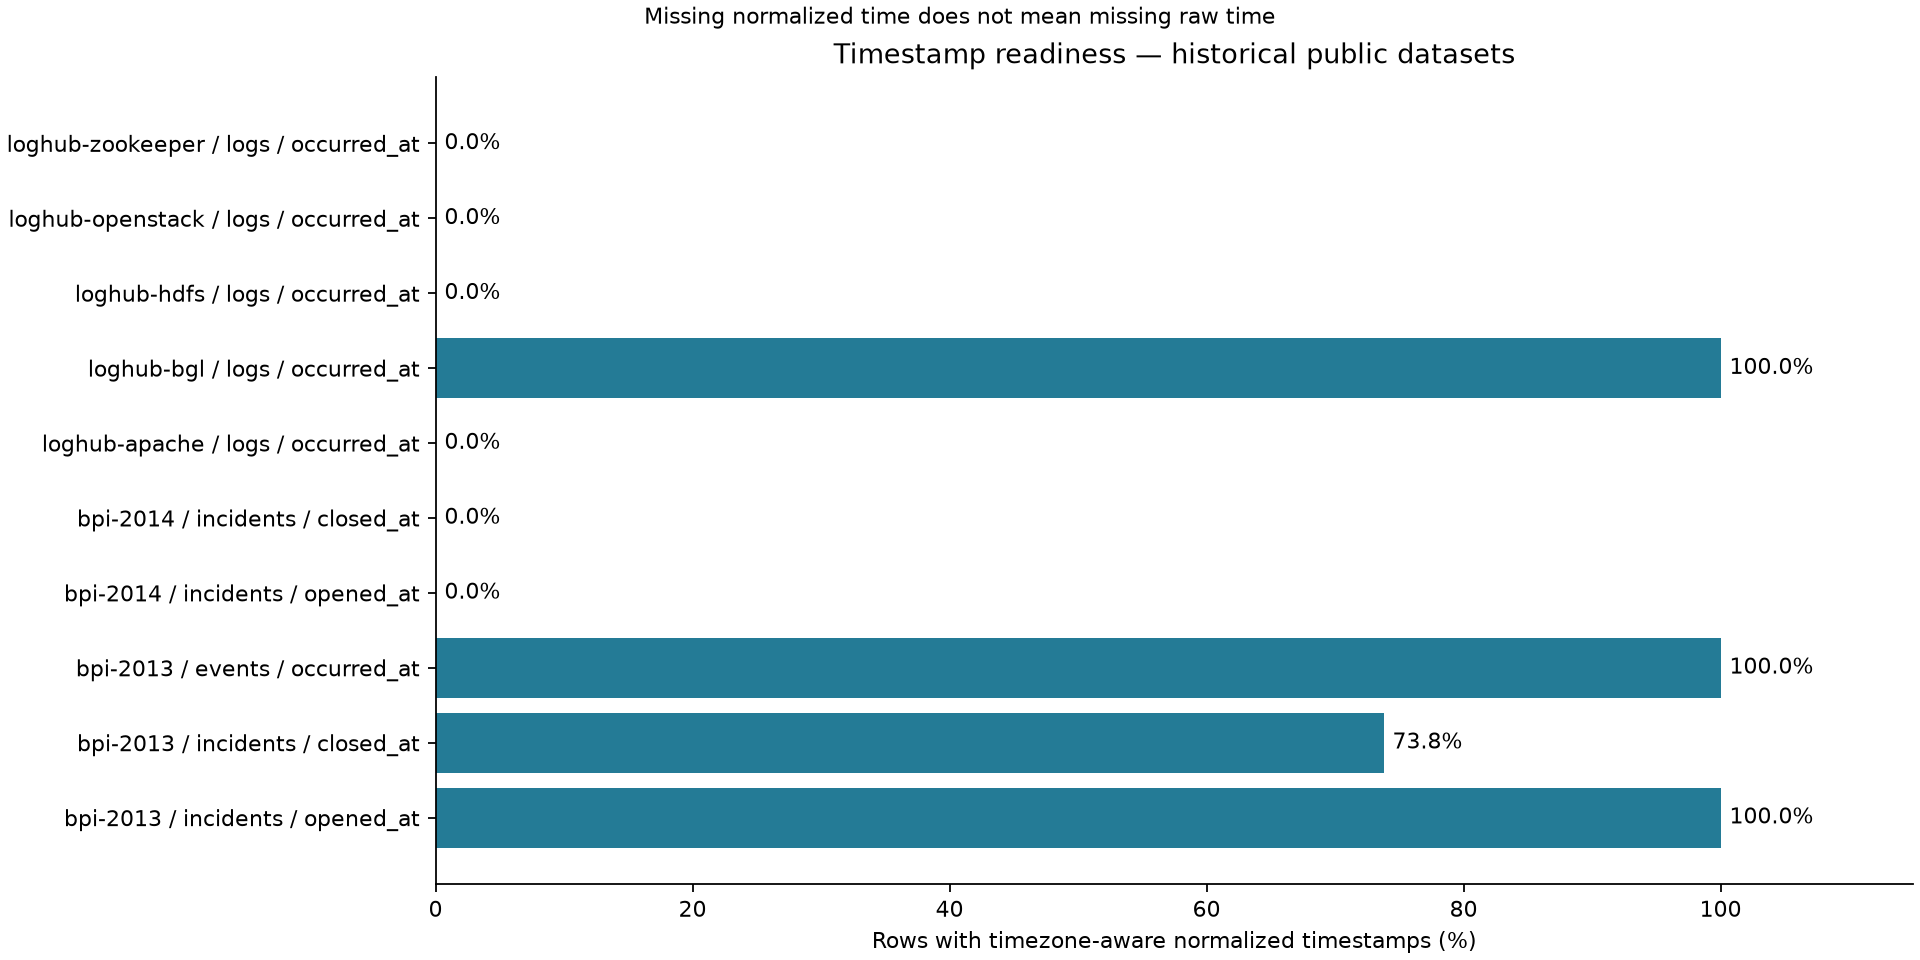

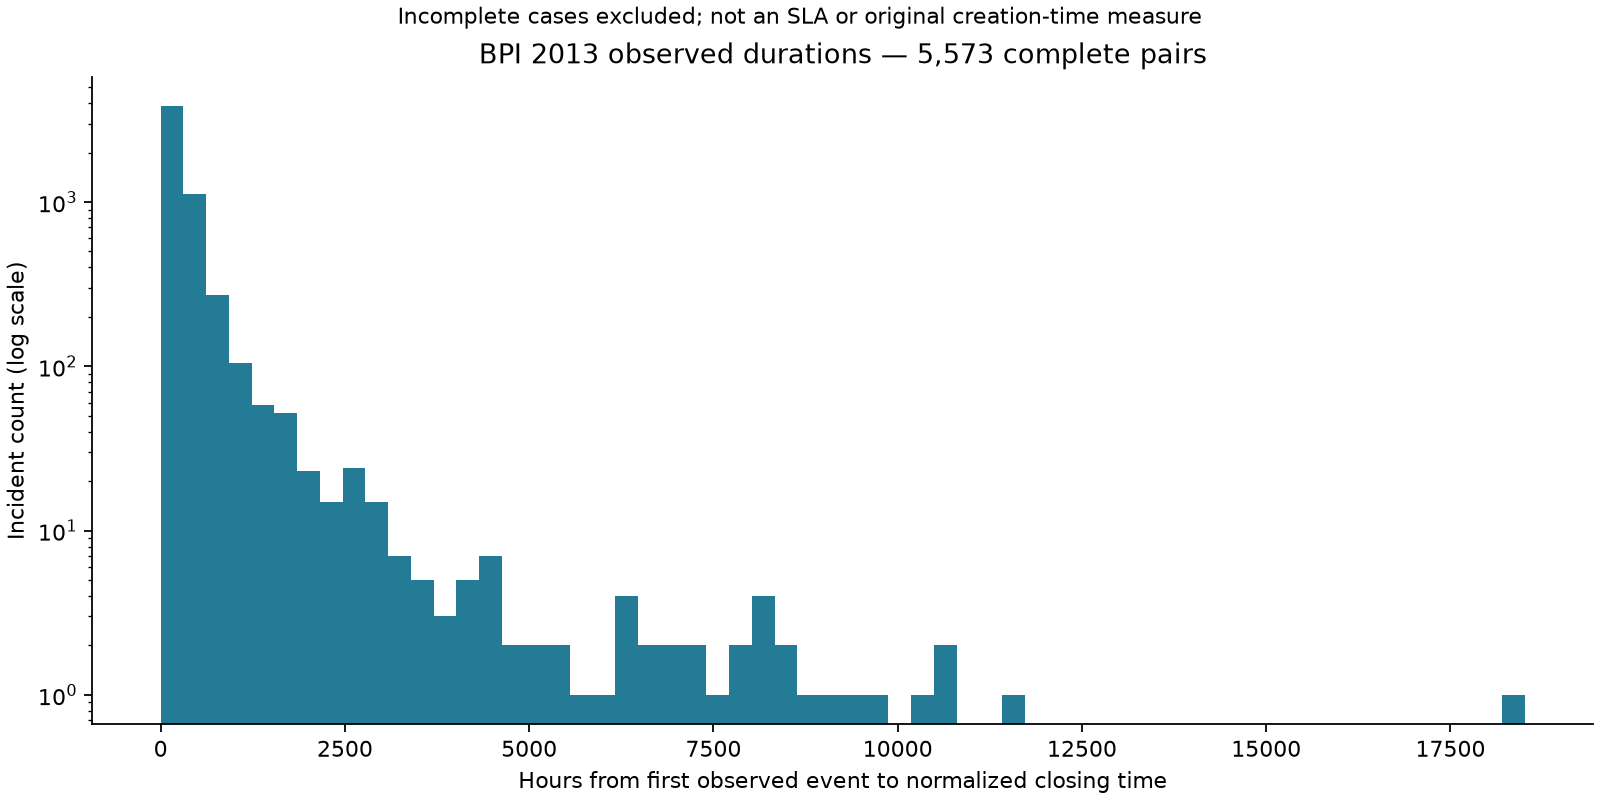

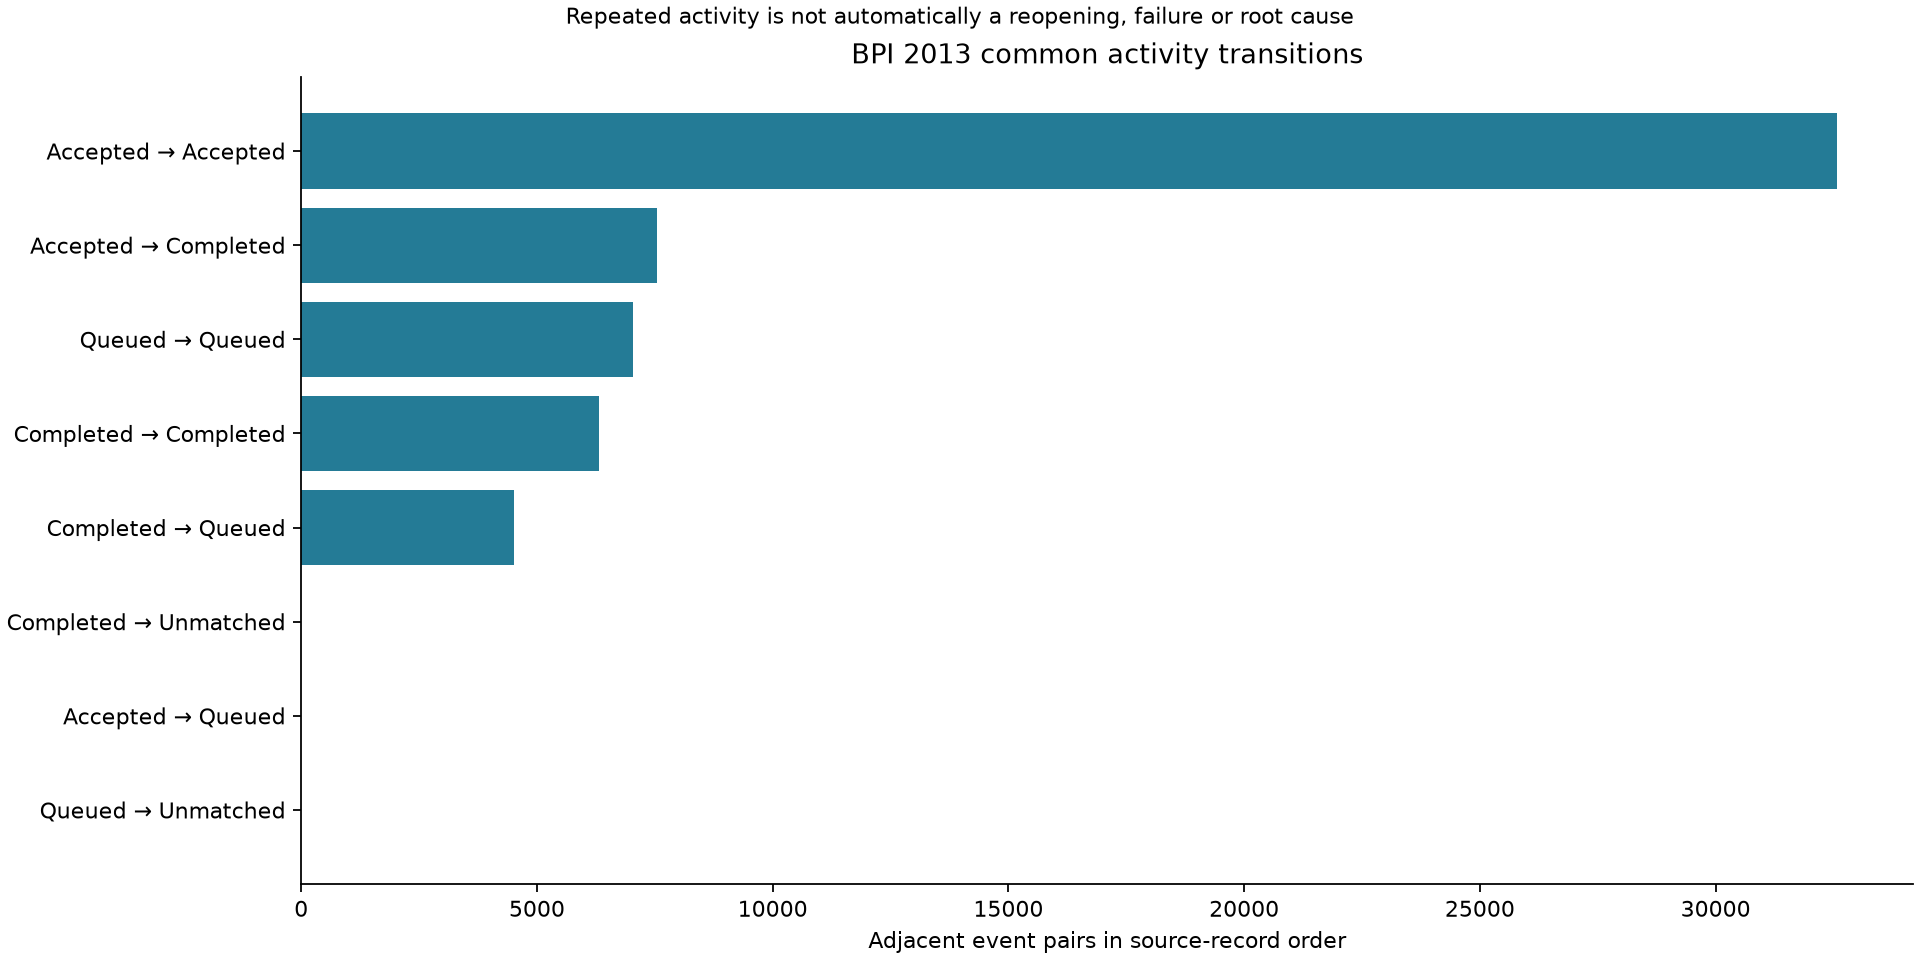

In [4]:
from IPython.display import Image, display

for name in [
    "01-timestamp-readiness.png",
    "02-observed-durations.png",
    "03-activity-transitions.png",
]:
    display(Image(filename=str(Path("docs/evidence/eda") / name)))

## Agent readiness decision
We can support source-scoped statistics and evidence retrieval. We cannot establish cross-dataset root causes, real SLA breaches, remediation success or agent performance from these samples. Next: review source-state semantics, verify persistence/replay and create related, human-reviewed investigation cases. Compare a tool-using agent with search-and-summary before adding more agents.